# 02 · Boom Catalogue (Phase P2, part 3)

Turns the outcome panel into a dated catalogue of **takeoffs, booms, spikes and lifecycle stages**, using the
rules frozen in `PREREGISTRATION.md` §2 (with the deviations logged in §9).

| Section | What happens |
|---|---|
| 1 | Load the outcome series and your blind visual codes |
| 2 | Fit the takeoff threshold `g*(L) = a·L^(−b)` with minimum base `L_min` on the **calibration half** |
| 3 | **Validate** on the other half (pre-registered bar: ≥ 75% agreement within ±1 year) |
| 4 | Robustness: the two alternative takeoff rules from Golder & Tellis (1997, appendix) |
| 5 | Slowdown (Stremersch & Tellis 2004 rule), boom / spike / stage for every series |
| 6 | Origin attribution (descriptive) |
| 7 | The catalogue |

In [1]:
import sys, json, itertools, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

sys.path.insert(0, str(Path.cwd().parent))
from drivers.config import PROC, FIG, ROOT, NAME, COUNTRIES
from drivers import fetch
warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)

## 1 · Series and visual codes
Code positions: **1 = "start"** ("before" or "Y1": already growing when the data begins), **k** = takeoff in year Yk,
**none** = no takeoff. Y1 cannot be a detectable takeoff (there is no earlier year to grow from), so it shares the
"start" category with "before" (deviation logged).

In [2]:
P = pd.read_parquet(PROC / "outcome_panel.parquet")
P = P[~P.is_estimate]
key = pd.read_parquet(PROC / "coding_key.parquet")
codes = pd.read_csv(ROOT / "data" / "public" / "manual" / "visual_codes.csv")
key = key.merge(codes, on="chart_id", how="left")
assert key.code.notna().all(), "uncoded charts"

def code_pos(c):
    c = str(c).strip()
    if c in ("before", "Y1"): return 1
    if c == "none": return None
    return int(c[1:])
key["visual_pos"] = pd.Series([code_pos(c) for c in key.code], index=key.index, dtype=object)   # keep None, not NaN

SER = {}
for _, r in key.iterrows():
    g = P[(P.series == r.series) & (P.iso3 == r.iso3)].sort_values("year")
    SER[r.chart_id] = (g.year.to_numpy(), g.value.to_numpy())
key["unit"] = key.series.map(P.drop_duplicates("series").set_index("series").unit)
key["fit_group"] = np.where(key.unit.str.contains("% of GDP"), key.group, "visual_only")
print(key.groupby(["fit_group", "half"]).size().unstack(fill_value=0))
print("\nvisual codes:", key.code.map(lambda c: "start" if c in ("before", "Y1") else ("none" if c == "none" else "year")).value_counts().to_dict())

half         calibration  validation
fit_group                           
digital               12          12
fintech                6           5
visual_only            1           1

visual codes: {'start': 13, 'none': 13, 'year': 11}


## 2 · Fit the threshold rule on the calibration half
Takeoff = first year *t* with `L[t−1] ≥ L_min` and growth `x[t]/x[t−1] − 1 ≥ a · L[t−1]^(−b)`.
A crossing in the first computable year (Y2) means the series was already taking off at the start, so it maps to
position 1. The grid search maximises **exact** agreement, then **±1-year** agreement, then simplicity (smaller b,
then smaller L_min).

In [3]:
def rule_pos(x, a, b, Lmin):
    for t in range(1, len(x)):
        base = x[t - 1]
        if base <= 0 or base < Lmin:
            continue
        if x[t] / base - 1 >= a * base ** (-b):
            return 1 if t == 1 else t + 1          # t is 0-based; positions are 1-based
    return None

def agree_original(p, v, tol):
    """As pre-registered: 'start' (1), a year (k) and 'none' are three different answers."""
    if p is None or v is None: return p is None and v is None
    return abs(p - v) <= tol

def no_date(p):
    return p is None or p == 1

def agree(p, v, tol):
    """Revision A (2026-10-08, logged): 'start' and 'none' merge into 'no datable takeoff in the window'.
    Both answers mean that no takeoff can be dated inside the observed years."""
    if no_date(p) or no_date(v): return no_date(p) and no_date(v)
    return abs(p - v) <= tol

A = np.round(np.concatenate([np.arange(0.05, 1.0, 0.05), np.arange(1.0, 3.01, 0.25)]), 3)
B = np.round(np.arange(0, 1.01, 0.1), 2)
fits = {}
for grp in ["fintech", "digital"]:
    cal = key[(key.fit_group == grp) & (key.half == "calibration")]
    allL = np.concatenate([SER[i][1] for i in key[key.fit_group == grp].chart_id])
    Lgrid = np.unique(np.round(np.quantile(allL[allL > 0], [0, .1, .2, .3, .4, .5]), 4))
    Lgrid = np.concatenate([[0.0], Lgrid])
    best = None
    for a, b, Lmin in itertools.product(A, B, Lgrid):
        preds = [rule_pos(SER[i][1], a, b, Lmin) for i in cal.chart_id]
        ex = np.mean([agree(p, v, 0) for p, v in zip(preds, cal.visual_pos)])
        pm = np.mean([agree(p, v, 1) for p, v in zip(preds, cal.visual_pos)])
        score = (ex, pm, -b, -Lmin)
        if best is None or score > best[0]:
            best = (score, dict(a=float(a), b=float(b), L_min=float(Lmin), cal_exact=ex, cal_pm1=pm, n_cal=len(cal)))
    fits[grp] = best[1]
fits_df = pd.DataFrame(fits).T
(PROC / "threshold_params.json").write_text(json.dumps(fits, indent=2))
fits_df

,a,b,L_min,cal_exact,cal_pm1,n_cal
fintech,0.15,0.4,0.0267,0.500000,0.5,6.0
digital,0.25,0.0,0.0000,0.833333,1.0,12.0


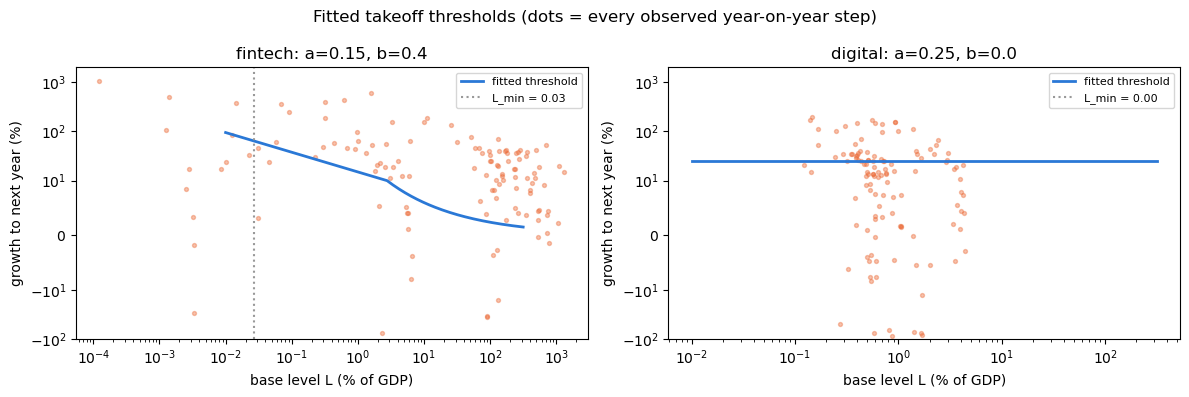

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, grp in zip(axes, ["fintech", "digital"]):
    f = fits[grp]
    L = np.logspace(-2, 2.5, 200)
    ax.plot(L, f["a"] * L ** (-f["b"]) * 100, color="#2a78d6", lw=2, label="fitted threshold")
    ax.axvline(f["L_min"], color="#999", ls=":", label=f"L_min = {f['L_min']:.2f}")
    for i in key[key.fit_group == grp].chart_id:
        x = SER[i][1]; base, gr = x[:-1], x[1:] / np.where(x[:-1] > 0, x[:-1], np.nan) - 1
        ax.scatter(base, gr * 100, s=8, alpha=.4, color="#eb6834")
    ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=10); ax.set_ylim(-100, 2000)
    ax.set_xlabel("base level L (% of GDP)"); ax.set_ylabel("growth to next year (%)")
    ax.set_title(f"{grp}: a={f['a']}, b={f['b']}"); ax.legend(fontsize=8)
plt.suptitle("Fitted takeoff thresholds (dots = every observed year-on-year step)")
plt.tight_layout(); plt.savefig(FIG / "02_threshold_fit.png", dpi=150); plt.show()

## 3 · Validation on the held-out half
**Revision A** (decided in the P2 review after the first run failed): the first run scored 50% (digital) and 60%
(fintech) on the validation half. Almost every miss was a series you coded "no takeoff" that the rule called
"already growing at start". Both mean *no takeoff can be dated inside the window*, so they are merged. The rule
above is **refit** under the merged definition. Below, the agreement is reported **both ways**.

In [5]:
key["rule_pos"] = pd.Series([None] * len(key), index=key.index, dtype=object)
for grp, f in fits.items():
    idx = key.index[key.fit_group == grp]
    for j in idx:
        key.at[j, "rule_pos"] = rule_pos(SER[key.at[j, "chart_id"]][1], f["a"], f["b"], f["L_min"])
key["agree_exact"] = [agree(p, v, 0) for p, v in zip(key.rule_pos, key.visual_pos)]
key["agree_pm1"] = [agree(p, v, 1) for p, v in zip(key.rule_pos, key.visual_pos)]
key["agree_pm1_original_def"] = [agree_original(p, v, 1) for p, v in zip(key.rule_pos, key.visual_pos)]
val = (key[key.fit_group != "visual_only"].groupby(["fit_group", "half"])
          .agg(n=("chart_id", "count"), exact=("agree_exact", "mean"), within_1yr=("agree_pm1", "mean"),
               within_1yr_original_definition=("agree_pm1_original_def", "mean")).round(2))
val["passes_75pct_bar"] = np.where(val.index.get_level_values("half") == "validation", val.within_1yr >= 0.75, "")
val

n  exact  within_1yr  within_1yr_original_definition passes_75pct_bar
fit_group half                                                                               
digital   calibration  12   0.83        1.00                            0.83                 
          validation   12   0.83        0.92                            0.50             True
fintech   calibration   6   0.50        0.50                            0.50                 
          validation    5   0.80        0.80                            0.60             True

In [6]:
dis = key[(key.fit_group != "visual_only") & (~key.agree_pm1)]
print(f"{len(dis)} disagreements under revision A (visual vs rule positions; 1 or None = no datable takeoff):")
dis[["chart_id", "half", "series", "iso3", "code", "visual_pos", "rule_pos"]]

5 disagreements under revision A (visual vs rule positions; 1 or None = no datable takeoff):


,chart_id,half,series,iso3,code,visual_pos,rule_pos
2,S03,calibration,fas_mobile_banking,IDN,Y8,8,4
4,S05,validation,econsea_online_travel,SGP,none,None,4
11,S12,calibration,fas_mobile_money,MMR,Y5,5,1
15,S16,validation,fas_mobile_money,KHM,Y9,9,3
17,S18,calibration,fas_mobile_banking,THA,Y8,8,1


## 4 · Robustness: alternative takeoff rules (Golder & Tellis 1997, appendix)
* **Logistic-curve rule:** fit a 3-parameter logistic; takeoff = year of the maximum second derivative,
  i.e. `t0 − ln(2 + √3)/k`.
* **Maximum-growth rule:** the largest % increase within 3 years of the logistic takeoff.

Both use the whole series, so they involve hindsight, as the 1997 paper notes. With 6-year series many
logistic fits fail, and those are reported as such.

In [7]:
def logistic(t, K, k, t0): return K / (1 + np.exp(-k * (t - t0)))
def alt_rules(years, x):
    t = np.arange(len(x), dtype=float)
    try:
        (K, k, t0), _ = curve_fit(logistic, t, x, p0=[x.max() * 1.5, 1.0, len(x) / 2], maxfev=20000,
                                  bounds=([x.max() * 0.5, 0.05, -10], [x.max() * 20, 10, len(x) + 10]))
        tl = t0 - np.log(2 + np.sqrt(3)) / k
        if not (0 <= tl <= len(x) - 1): return "outside data", None
        log_pos = int(round(tl)) + 1
        g = x[1:] / np.where(x[:-1] > 0, x[:-1], np.nan) - 1
        win = range(max(log_pos - 1, 1), min(log_pos + 3, len(x)))
        mg = max(win, key=lambda j: np.nan_to_num(g[j - 1], nan=-9)) + 1 if len(win) else None
        return log_pos, mg
    except Exception:
        return "fit failed", None
alt = pd.DataFrame([dict(chart_id=i, **dict(zip(["logistic_pos", "maxgrowth_pos"], alt_rules(*SER[i])))) for i in key.chart_id])
key = key.merge(alt, on="chart_id")
num = key[key.logistic_pos.map(lambda v: isinstance(v, (int, np.integer)))]
print("logistic rule: fitted for", len(num), "of", len(key), "series")
for col in ["logistic_pos", "maxgrowth_pos"]:
    ok = num.dropna(subset=[col])
    print(f"  {col}: within ±1 of visual code in {np.mean([agree(int(p), v, 1) for p, v in zip(ok[col], ok.visual_pos)]):.0%} of {len(ok)}")

logistic rule: fitted for 7 of 37 series
  logistic_pos: within ±1 of visual code in 29% of 7
  maxgrowth_pos: within ±1 of visual code in 14% of 7


## 5 · Slowdown, boom, spike and lifecycle stages
* **Takeoff:** rule position for % of GDP series; visual code for the 2 rail series.
* **End of growth** (Stremersch & Tellis 2004, stating the Golder & Tellis 2004 rule): the first year after takeoff
  after which two consecutive years are lower. **Slowdown** = the next year.
* **Boom:** ≥ 3 years from takeoff without slowdown. **Boom pending:** fewer than 3 years observed.
* **Spike (annual):** after takeoff, a fall > 50% from the peak within 2 years.
* **Start** takeoffs (already growing when data begins) are judged on the observed years from the start.

In [8]:
def window_trend(x):
    cagr = (x[-1] / x[0]) ** (1 / (len(x) - 1)) - 1 if x[0] > 0 else np.nan
    return "growing" if cagr > 0.10 else ("declining" if cagr < -0.02 else "flat"), cagr

def lifecycle(years, x, pos):
    pos = None if pos is None or (isinstance(pos, float) and np.isnan(pos)) else int(pos)
    n = len(x); out = dict(takeoff_pos=pos)
    if no_date(pos):                                                 # revision A
        trend, cagr = window_trend(x)
        return dict(out, status=f"no datable takeoff ({trend} through window)", takeoff_year=None,
                    slowdown_year=None, growth_years=0, window_cagr=round(float(cagr), 3) if cagr == cagr else None,
                    stages=["no datable takeoff"] * n)
    t0 = pos - 1                                                     # 0-based takeoff index (start -> 0)
    end = None
    for t in range(t0, n - 2):
        if x[t + 1] < x[t] and x[t + 2] < x[t]:
            end = t; break
    slow = end + 1 if end is not None else None
    peak_i = int(np.argmax(x[t0:])) + t0
    spike = any(x[j] < 0.5 * x[peak_i] for j in range(peak_i + 1, min(peak_i + 3, n)))
    growth_years = (end - t0 + 1) if end is not None else (n - t0)
    if spike: status = "spike"
    elif growth_years >= 3: status = "boom"
    elif end is None: status = "boom pending"
    else: status = "takeoff, slowed within 3 yrs"
    stages = []
    for t in range(n):
        if t < t0: stages.append("pre-takeoff")
        elif t == t0: stages.append("takeoff")
        elif slow is None or t < slow: stages.append("growth")
        else:
            gr = x[t] / x[t - 1] - 1 if x[t - 1] > 0 else 0
            last3 = [x[j] < x[j - 1] for j in range(max(t - 2, 1), t + 1)]
            stages.append("decline" if len(last3) == 3 and all(last3) else ("maturity" if abs(gr) < 0.10 else "slowdown"))
    return dict(out, status=status, takeoff_year=int(years[t0]), window_cagr=None,
                slowdown_year=int(years[slow]) if slow is not None else None, growth_years=growth_years, stages=stages)

rows, stage_rows = [], []
for _, r in key.iterrows():
    yrs, x = SER[r.chart_id]
    pos = r.visual_pos if r.fit_group == "visual_only" else r.rule_pos
    lc = lifecycle(yrs, x, pos)
    rows.append(dict(chart_id=r.chart_id, group=r.group, series=r.series, iso3=r.iso3, country=NAME[r.iso3],
                     first_year=int(yrs[0]), last_year=int(yrs[-1]), basis="visual" if r.fit_group == "visual_only" else "rule",
                     **{k: v for k, v in lc.items() if k != "stages"}))
    stage_rows += [dict(series=r.series, iso3=r.iso3, year=int(y), stage=s) for y, s in zip(yrs, lc["stages"])]
cat = pd.DataFrame(rows); stages = pd.DataFrame(stage_rows)

## 6 · Origin attribution (descriptive, fintech only)
Origin countries (US, China, India) are dated with the **same fitted fintech rule** on their own IMF FAS series.
e-Conomy SEA covers only SEA, so digital sectors can be compared only *within* SEA, and most took off before 2019,
so they stay unattributed.

In [9]:
fas = fetch.fetch_imf_fas()
FASMAP = {"fas_mobile_money": "mobile_money_tx_value_pct_gdp", "fas_mobile_banking": "mobile_internet_banking_tx_value_pct_gdp"}
f = fits["fintech"]
origin_takeoff = {}
for s, ind in FASMAP.items():
    for c in ["USA", "CHN", "IND"]:
        g = fas[(fas.iso3 == c) & (fas.indicator == ind)].dropna(subset=["value"]).sort_values("year")
        if len(g) >= 5:
            p = rule_pos(g.value.to_numpy(), f["a"], f["b"], f["L_min"])
            origin_takeoff[(s, c)] = (int(g.year.iloc[p - 1]) if p and p > 1 else None, int(g.year.iloc[0]), p)
print({f"{k[0]}|{k[1]}": v for k, v in origin_takeoff.items()})

def dated(y):
    return y is not None and not (isinstance(y, float) and np.isnan(y))

def attribute(r):
    if not dated(r.takeoff_year): return "unattributed (no dated takeoff)"
    T = int(r.takeoff_year)
    cands = [(y, c) for (s, c), (y, _, _) in origin_takeoff.items() if s == r.series and y is not None and y <= T - 1]
    cands += [(int(o.takeoff_year), o.iso3) for _, o in cat[(cat.series == r.series) & (cat.iso3 != r.iso3)].iterrows()
              if dated(o.takeoff_year) and o.takeoff_year <= T - 1]
    if not cands: return "SEA-native / first mover"
    y, c = min(cands)
    return f"{'intra-SEA' if c in COUNTRIES else 'origin'}: {c} ({y})"
cat["origin"] = cat.apply(attribute, axis=1)

{'fas_mobile_money|IND': (2016, 2013, 4), 'fas_mobile_banking|IND': (2014, 2012, 3)}


## 6b · Series added after sheet 1 (coding sheet 2)
* **Passport online food ordering** (% of GDP): dated with the **frozen** digital rule, with no refitting. Agreement
  with your blind sheet-2 codes is an **out-of-sample test** of that rule.
* **Orbis new firms per year** (crypto, fintech): dated by your **visual code** only, because the unit (firms) is not
  % of GDP. Survivorship caveat: the export holds active firms only.

This section runs only once `data/public/manual/visual_codes_2.csv` exists.

In [10]:
codes2_f = ROOT / "data" / "public" / "manual" / "visual_codes_2.csv"
LICD = ROOT / "data" / "licensed" / "derived"
if codes2_f.exists():
    key2 = pd.read_parquet(PROC / "coding_key_2.parquet").merge(pd.read_csv(codes2_f), on="chart_id", how="left")
    assert key2.code.notna().all(), "uncoded charts in sheet 2"
    key2["visual_pos"] = pd.Series([code_pos(c) for c in key2.code], index=key2.index, dtype=object)
    pp = pd.read_parquet(LICD / "passport_food_online_ordering.parquet")
    ff = pd.read_parquet(LICD / "orbis_firm_formation_PRELIMINARY.parquet")
    SER2 = {}
    for _, r in key2.iterrows():
        if r.series.startswith("passport"):
            g = pp[pp.iso3 == r.iso3].sort_values("year"); SER2[r.chart_id] = (g.year.to_numpy(), g.value.to_numpy())
        else:
            kind = r.series.split("_")[2]
            g = ff[(ff.kind == kind) & (ff.iso3 == r.iso3)].sort_values("year")
            SER2[r.chart_id] = (g.year.to_numpy(), g.new_firms.to_numpy(dtype=float))
    fd = fits["digital"]
    key2["rule_pos"] = pd.Series([rule_pos(SER2[i][1], fd["a"], fd["b"], fd["L_min"]) if s.startswith("passport") else None
                                  for i, s in zip(key2.chart_id, key2.series)], index=key2.index, dtype=object)
    pas = key2[key2.series.str.startswith("passport")]
    oos = pd.Series(dict(n=len(pas), exact=np.mean([agree(p, v, 0) for p, v in zip(pas.rule_pos, pas.visual_pos)]),
                         within_1yr=np.mean([agree(p, v, 1) for p, v in zip(pas.rule_pos, pas.visual_pos)])))
    print("Out-of-sample test of the frozen digital rule on Passport food delivery:"); print(oos.round(2).to_string())
    add_rows = []
    for _, r in key2.iterrows():
        yrs, x = SER2[r.chart_id]
        basis = "rule" if r.series.startswith("passport") else "visual"
        pos = r.rule_pos if basis == "rule" else r.visual_pos
        lc = lifecycle(yrs, x, pos)
        add_rows.append(dict(chart_id=r.chart_id, group=r.group, series=r.series, iso3=r.iso3, country=NAME[r.iso3],
                             first_year=int(yrs[0]), last_year=int(yrs[-1]), basis=basis,
                             **{k: v for k, v in lc.items() if k != "stages"}))
        stages = pd.concat([stages, pd.DataFrame([dict(series=r.series, iso3=r.iso3, year=int(y), stage=s)
                                                 for y, s in zip(yrs, lc["stages"])])], ignore_index=True)
    add = pd.DataFrame(add_rows); add["origin"] = "not attributed (added series)"
    # Orbis registers new firms with a lag, so the last year (2025) is likely incomplete. Flag statuses that change
    # when it is dropped (sensitivity only; the pre-registered rule is not changed).
    add["note"] = ""
    for idx, r in add.iterrows():
        if r.series.startswith("orbis"):
            yrs, x = SER2[r.chart_id]
            pos = key2.loc[key2.chart_id == r.chart_id, "visual_pos"].iloc[0]
            alt = lifecycle(yrs[:-1], x[:-1], pos)["status"]
            if alt != r.status:
                add.loc[idx, "note"] = f"fragile: '{alt}' if incomplete {int(yrs[-1])} is dropped"
    cat = pd.concat([cat, add], ignore_index=True)
    key = pd.concat([key, key2.assign(fit_group=np.where(key2.series.str.startswith("passport"), "digital_oos", "visual_only"))],
                    ignore_index=True)
    display(add[["series", "country", "basis", "takeoff_year", "slowdown_year", "growth_years", "status", "note"]])
else:
    print("visual_codes_2.csv not found yet: sheet-2 series not added")

Out-of-sample test of the frozen digital rule on Passport food delivery:
n             6.00
exact         0.83
within_1yr    0.83


,series,country,basis,takeoff_year,slowdown_year,growth_years,status,note
0,passport_food_online_ordering,Thailand,rule,NaN,NaN,0,no datable takeoff (flat through window),
1,passport_food_online_ordering,Philippines,rule,NaN,NaN,0,no datable takeoff (flat through window),
2,orbis_new_fintech_firms,Singapore,visual,NaN,NaN,0,no datable takeoff (growing through window),
3,orbis_new_crypto_firms,Thailand,visual,2019.0,2023.0,4,spike,
4,passport_food_online_ordering,Malaysia,rule,NaN,NaN,0,no datable takeoff (growing through window),
5,passport_food_online_ordering,Vietnam,rule,NaN,NaN,0,no datable takeoff (growing through window),
6,orbis_new_fintech_firms,Cambodia,visual,2014.0,2019.0,5,spike,
7,orbis_new_crypto_firms,Vietnam,visual,2014.0,2019.0,5,spike,
8,orbis_new_crypto_firms,Singapore,visual,2016.0,2019.0,3,spike,
9,orbis_new_crypto_firms,Indonesia,visual,2019.0,2024.0,5,spike,fragile: 'boom' if incomplete 2025 is dropped


## 7 · The catalogue

In [11]:
def as_text(df):            # mixed int/str columns (e.g. takeoff year "≤2019") are stored as text
    return df.assign(**{c: df[c].map(lambda v: None if v is None else str(v)) for c in df.columns if df[c].dtype == object})
as_text(cat).to_parquet(PROC / "boom_catalogue.parquet"); stages.to_parquet(PROC / "lifecycle_stages.parquet")
as_text(key).to_parquet(PROC / "takeoff_coding_results.parquet")
print(cat.status.value_counts().to_string())
cat.sort_values(["group", "series", "iso3"])[["series", "country", "first_year", "last_year", "basis", "takeoff_year",
                                              "slowdown_year", "growth_years", "status", "origin"]]

status
no datable takeoff (growing through window)      25
boom                                             11
spike                                            10
no datable takeoff (flat through window)          7
no datable takeoff (declining through window)     2


,series,country,first_year,last_year,basis,takeoff_year,slowdown_year,growth_years,status,origin
46,orbis_new_crypto_firms,Indonesia,2005,2025,visual,2019.0,2024.0,5,spike,not attributed (added series)
53,orbis_new_crypto_firms,Malaysia,2005,2025,visual,2016.0,2019.0,3,spike,not attributed (added series)
45,orbis_new_crypto_firms,Singapore,2005,2025,visual,2016.0,2019.0,3,spike,not attributed (added series)
40,orbis_new_crypto_firms,Thailand,2005,2025,visual,2019.0,2023.0,4,spike,not attributed (added series)
44,orbis_new_crypto_firms,Vietnam,2005,2025,visual,2014.0,2019.0,5,spike,not attributed (added series)
7,econsea_ecommerce,Indonesia,2019,2024,rule,NaN,NaN,0,no datable takeoff (growing through window),unattributed (no dated takeoff)
25,econsea_ecommerce,Malaysia,2019,2024,rule,NaN,NaN,0,no datable takeoff (growing through window),unattributed (no dated takeoff)
8,econsea_ecommerce,Philippines,2019,2024,rule,NaN,NaN,0,no datable takeoff (growing through window),unattributed (no dated takeoff)
9,econsea_ecommerce,Singapore,2019,2024,rule,NaN,NaN,0,no datable takeoff (growing through window),unattributed (no dated takeoff)
33,econsea_ecommerce,Thailand,2019,2024,rule,NaN,NaN,0,no datable takeoff (growing through window),unattributed (no dated takeoff)


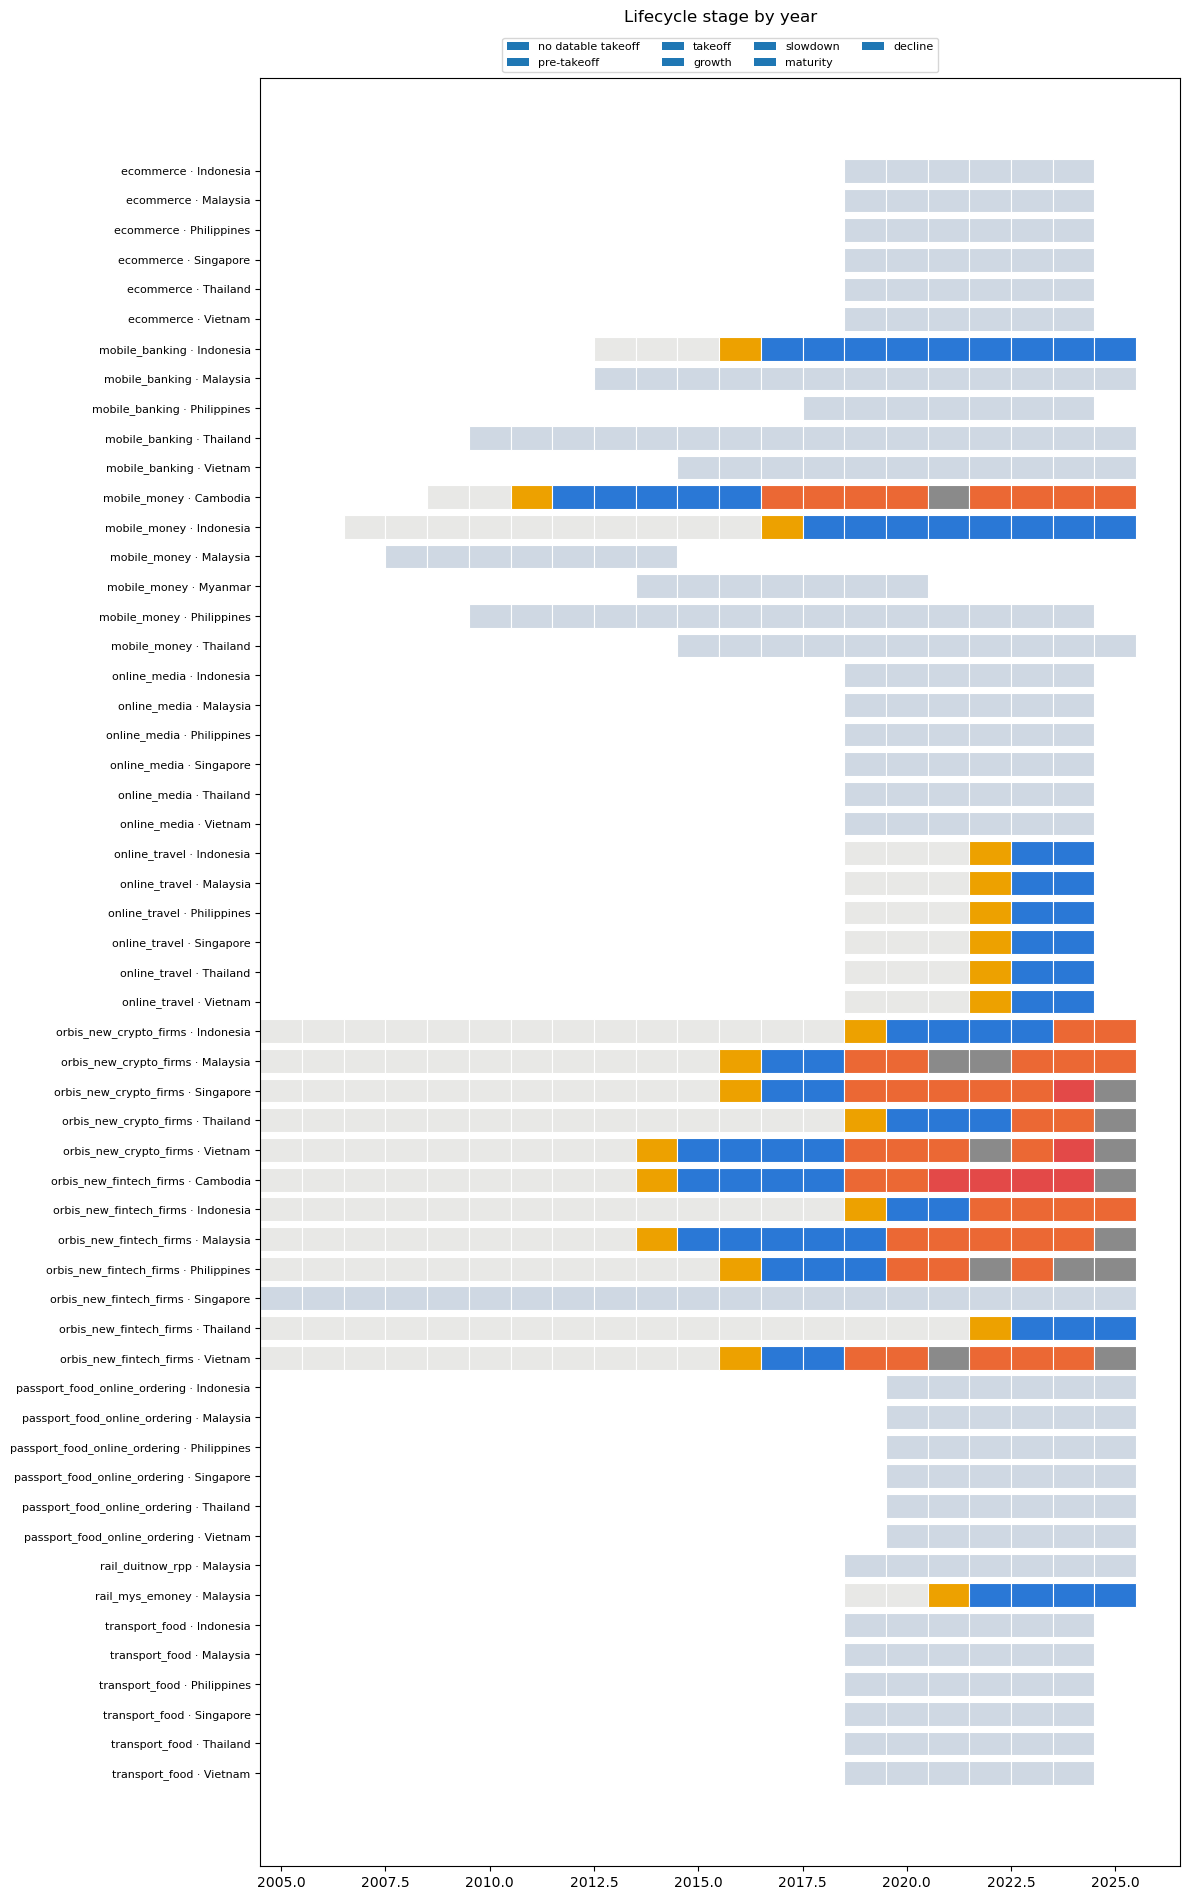

In [12]:
order = ["no datable takeoff", "pre-takeoff", "takeoff", "growth", "slowdown", "maturity", "decline"]
colors = {"no datable takeoff": "#cfd8e3", "pre-takeoff": "#e8e8e6", "takeoff": "#eda100", "growth": "#2a78d6",
          "slowdown": "#eb6834", "maturity": "#8a8a8a", "decline": "#e34948"}
st = stages.assign(row=stages.series.str.replace("econsea_", "").str.replace("fas_", "") + " · " + stages.iso3.map(NAME))
rows_ = sorted(st.row.unique())
fig, ax = plt.subplots(figsize=(12, 0.32 * len(rows_) + 1.5))
for i, rlab in enumerate(rows_):
    for _, s in st[st.row == rlab].iterrows():
        ax.barh(i, 1, left=s.year - 0.5, color=colors[s.stage], edgecolor="white", linewidth=0.8)
ax.set_yticks(range(len(rows_)), rows_, fontsize=8); ax.invert_yaxis()
for k in order: ax.barh([], [], color=colors[k], label=k)
ax.legend(ncol=4, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.set_title("Lifecycle stage by year", pad=40)
plt.tight_layout(); plt.savefig(FIG / "02_lifecycle_stages.png", dpi=150); plt.show()